First five records:
        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype

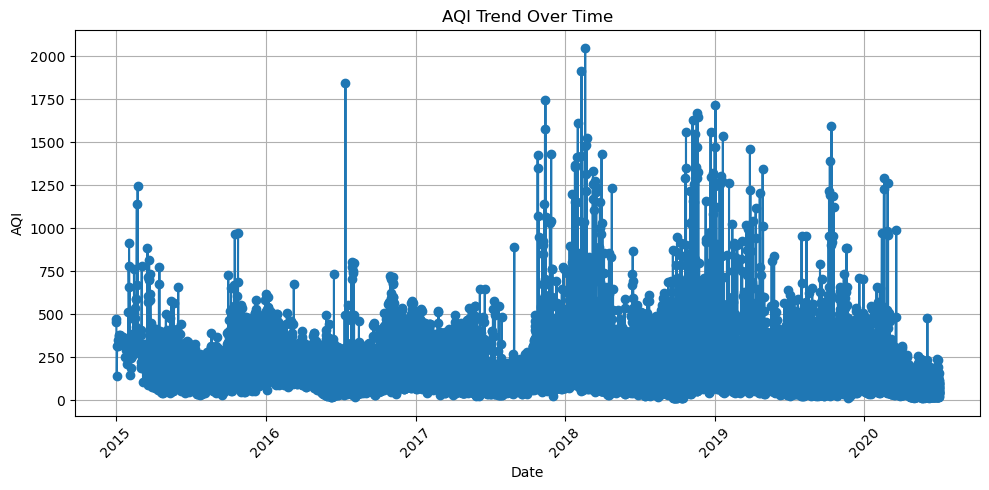

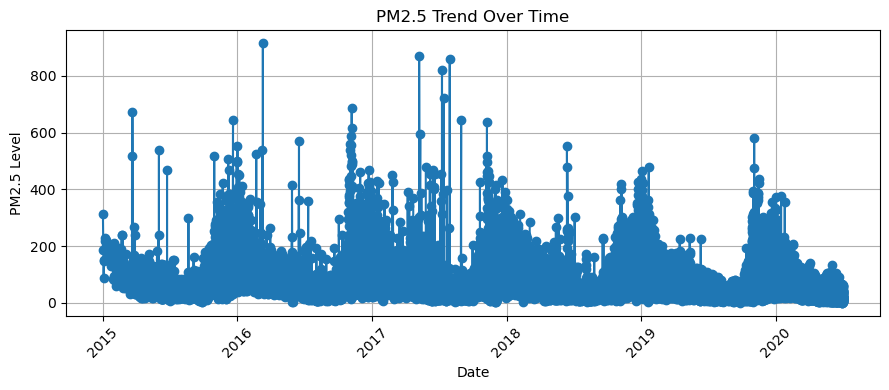

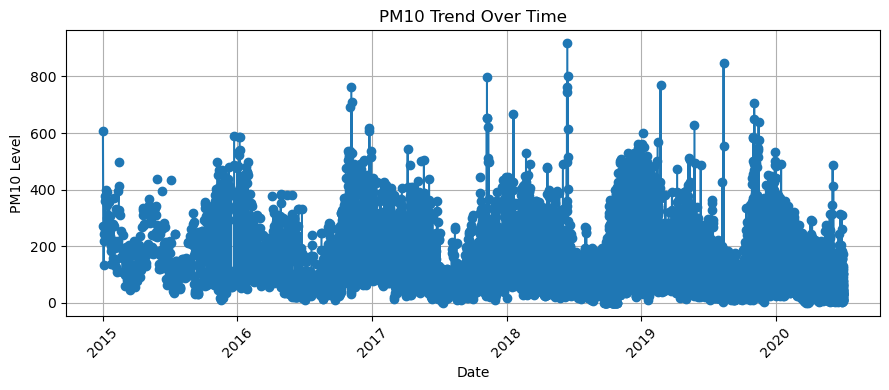

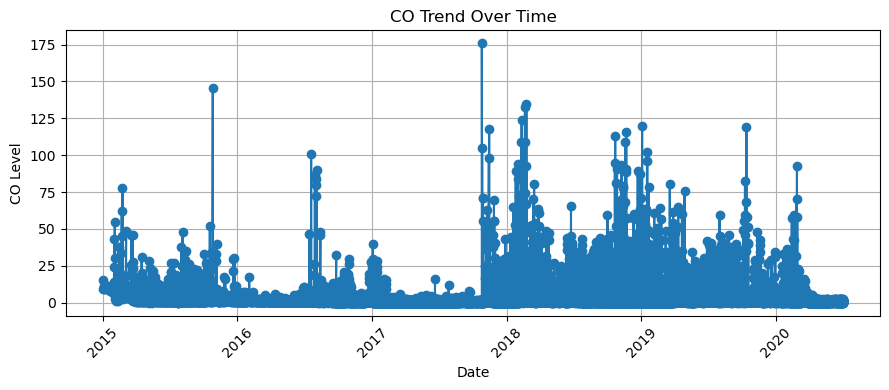

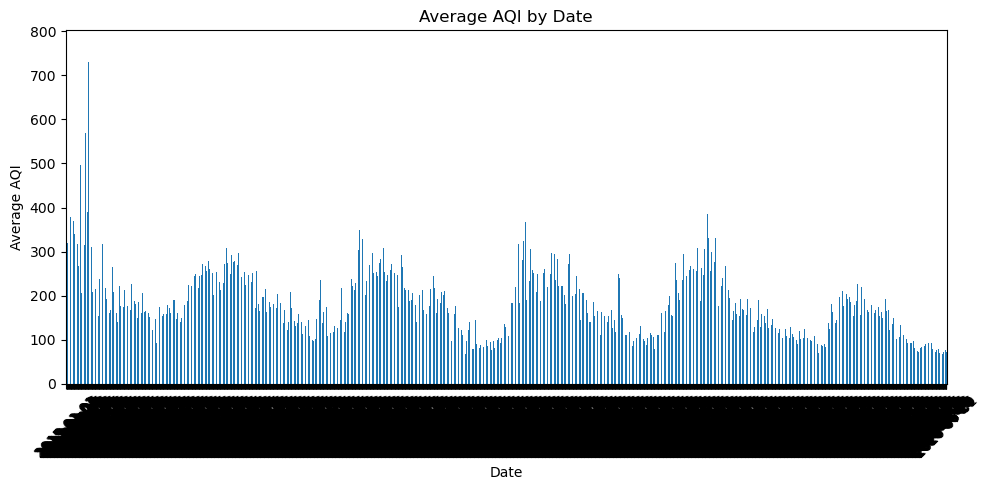

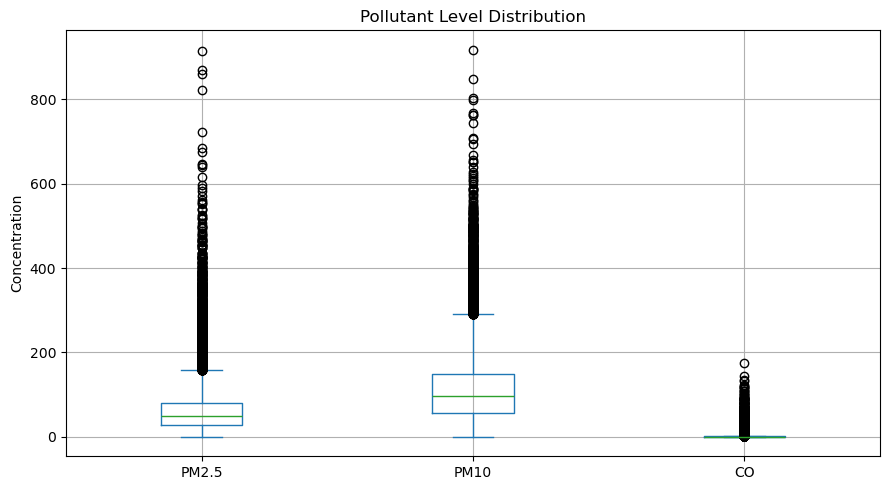

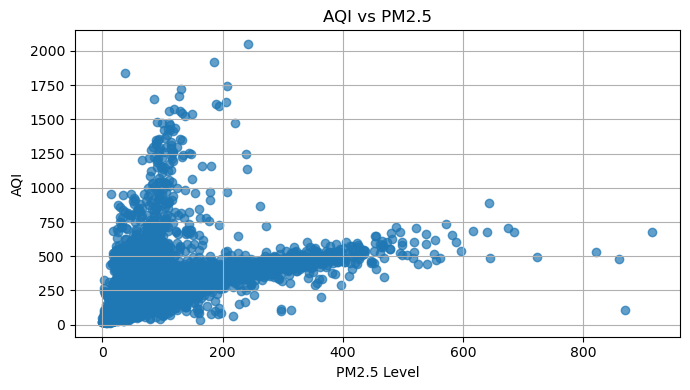

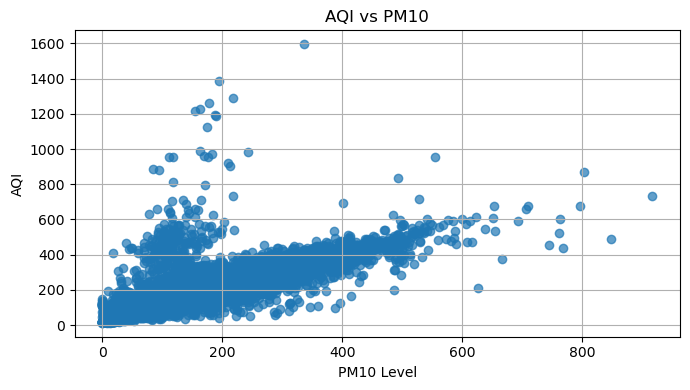

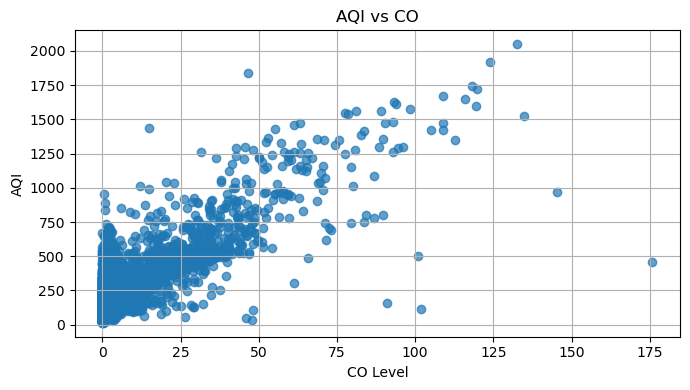

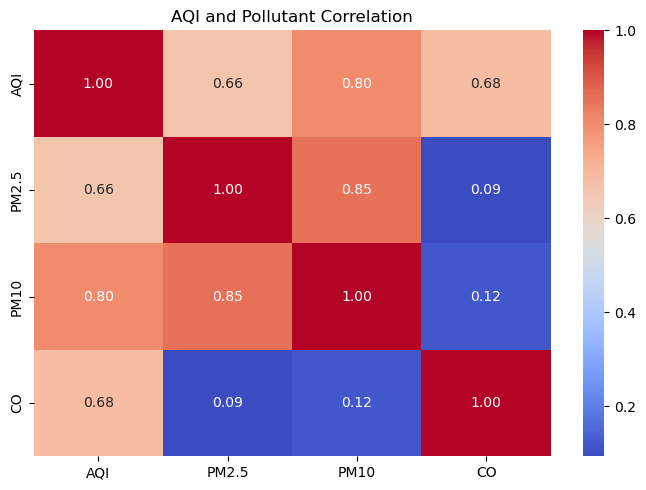


AQI visualization completed successfully.


In [2]:
#11.aqi_visualization.ipynb
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset
df = pd.read_csv("city_day.csv")

print("First five records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

# 2. Identify columns
df.columns = df.columns.str.strip()
date_col = next((c for c in df.columns
                 if c.lower() in ["date", "datetime", "timestamp"]), None)
aqi_col = next((c for c in df.columns
                if c.lower() == "aqi"), None)

if date_col is None or aqi_col is None:
    raise ValueError("Dataset must contain Date and AQI columns.")

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[aqi_col] = pd.to_numeric(df[aqi_col], errors="coerce")
df = df.dropna(subset=[date_col, aqi_col]).sort_values(date_col)

# Find pollutant columns
pollutants = [
    c for c in df.columns
    if c.lower().replace(" ", "") in
    ["pm2.5", "pm25", "pm10", "co"]
]

for col in pollutants:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nCleaned Data:")
print(df.head())

# 3. AQI trend line plot
plt.figure(figsize=(10, 5))
plt.plot(df[date_col], df[aqi_col], marker="o")
plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Individual pollutant trends
for col in pollutants:
    plt.figure(figsize=(9, 4))
    plt.plot(df[date_col], df[col], marker="o")
    plt.title(col + " Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel(col + " Level")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# 5. Bar plot: average AQI by date
daily_aqi = df.groupby(df[date_col].dt.date)[aqi_col].mean()

daily_aqi.plot(kind="bar", figsize=(10, 5))
plt.title("Average AQI by Date")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Box plot of pollutant distributions
if pollutants:
    df[pollutants].plot(
        kind="box", figsize=(9, 5), grid=True
    )
    plt.title("Pollutant Level Distribution")
    plt.ylabel("Concentration")
    plt.tight_layout()
    plt.show()

# 7. Scatter plots: AQI vs pollutants
for col in pollutants:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[col], df[aqi_col], alpha=0.7)
    plt.title("AQI vs " + col)
    plt.xlabel(col + " Level")
    plt.ylabel("AQI")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# 8. Correlation heatmap
numeric_cols = [aqi_col] + pollutants

if len(numeric_cols) > 1:
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("AQI and Pollutant Correlation")
    plt.tight_layout()
    plt.show()

print("\nAQI visualization completed successfully.")